# Municipal Complaint Classification

Compare four classifiers on labeled complaint text. The labels are Electricity, Health, Road, Sanitation, Transport, Water, and Other.

## 1. Problem definition
Classify complaint text into the seven categories. Compare models on a grouped development split; an exposed holdout is not used for tuning.

## 2. Data collection
Load the training data, optional provenance, and separate holdout for inspection only.

In [1]:
from pathlib import Path
import json, hashlib, platform, re, time

In [2]:
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [3]:
from sklearn import __version__ as sklearn_version
from sklearn.feature_extraction.text import TfidfVectorizer

In [4]:
from sklearn.pipeline import FeatureUnion, Pipeline
from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold

In [5]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay)

In [6]:
from sklearn.metrics.pairwise import cosine_similarity
from scipy.sparse.csgraph import connected_components
from IPython.display import display

In [7]:
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.ensemble import RandomForestClassifier

In [8]:
from backend.app.services.grievance_model import clean_text, CATEGORY_RENAME, GrievanceModel

In [9]:
SEED = 20261023
np.random.seed(SEED)
ROOT = Path.cwd()
if not (ROOT / 'backend').is_dir(): ROOT = ROOT.parent

In [10]:
DATA_PATH = ROOT / 'backend/data/municipal_complaints.csv'
PROVENANCE_PATH = ROOT / 'backend/data/municipal_complaints_synthetic_1100_provenance.csv'

In [11]:
HOLDOUT_PATH = Path.home() / 'Downloads/grievance_holdout_test_120.csv'
CANDIDATE_PATH = ROOT / 'backend/models/grievance_classifier_synthetic_research_simple_candidate_20261024.joblib'
METADATA_PATH = CANDIDATE_PATH.with_suffix('.metadata.json')

In [12]:
print('Python:', platform.python_version(), '| pandas:', pd.__version__, '| scikit-learn:', sklearn_version)
print('Random seed:', SEED)

Python: 3.13.7 | pandas: 3.0.5 | scikit-learn: 1.9.1
Random seed: 20261023


In [13]:
assert DATA_PATH.is_file(), DATA_PATH
raw = pd.read_csv(DATA_PATH, encoding='utf-8')
print('Shape:', raw.shape)
print('Columns:', raw.columns.tolist())

Shape: (1100, 2)
Columns: ['Complaint_Text', 'Category']


In [14]:
display(raw.head())
print('Data types:')
display(raw.dtypes)

,Complaint_Text,Category
0,Power keeps cutting out several times a day in...,Electricity
1,Our locality has frequent electricity interrup...,Electricity
2,The supply repeatedly goes off and returns aft...,Electricity
3,Bijli hamare area mein din bhar baar-baar ja r...,Electricity
4,Amchya bhagat divasbhar light satat jaate.,Electricity


Data types:


Complaint_Text    str
Category          str
dtype: object

In [15]:
print('Target classes:')
display(raw['Category'].value_counts(dropna=False).sort_index())

Target classes:


Category
Electricity    150
Health         150
Other          200
Road           150
Sanitation     150
Transport      150
Water          150
Name: count, dtype: int64

In [16]:
provenance = pd.read_csv(PROVENANCE_PATH) if PROVENANCE_PATH.is_file() else None
print('Provenance available:', provenance is not None)
if provenance is not None: display(provenance.head())

Provenance available: False


In [17]:
holdout = pd.read_csv(HOLDOUT_PATH) if HOLDOUT_PATH.is_file() else None
print('Separate holdout file found:', holdout is not None)
if holdout is not None: print('Holdout shape and columns:', holdout.shape, holdout.columns.tolist())

Separate holdout file found: True
Holdout shape and columns: (120, 2) ['complaint_text', 'category']


In [18]:
if holdout is not None:
    print('Holdout labels (inspection only):')
    display(holdout['category'].value_counts(dropna=False).sort_index() if 'category' in holdout else holdout.iloc[:, -1].value_counts(dropna=False))

Holdout labels (inspection only):


category
Electricity    17
Healthcare     17
Other          20
Roads          17
Sanitation     17
Transport      16
Water          16
Name: count, dtype: int64

## 3. Data cleaning and preprocessing
Keep original text; normalize labels and whitespace for modeling. Preserve negation and Devanagari.

In [19]:
data = raw[['Complaint_Text', 'Category']].rename(columns={'Complaint_Text':'text','Category':'category'}).copy()
data['text'] = data['text'].astype('string')
data['category'] = data['category'].astype('string').str.strip()

In [20]:
print('Missing values:')
display(data.isna().sum())
empty_text = data['text'].fillna('').str.strip().eq('')
print('Empty complaint texts:', int(empty_text.sum()))

Missing values:


text        0
category    0
dtype: int64

Empty complaint texts: 0


In [21]:
def duplicate_key(value):
    value = str(value).lower().strip()
    value = re.sub(r'[^\w\s]', ' ', value, flags=re.UNICODE)
    return re.sub(r'\s+', ' ', value).strip()

In [22]:
data['duplicate_key'] = data['text'].map(duplicate_key)
print('Exact duplicate excess:', int(data['text'].duplicated().sum()))
print('Normalized duplicate excess:', int(data['duplicate_key'].duplicated().sum()))

Exact duplicate excess: 0
Normalized duplicate excess: 0


In [23]:
data['category'] = data['category'].map(CATEGORY_RENAME).fillna(data['category'])
valid_labels = {'Electricity','Health','Road','Sanitation','Transport','Water','Other'}
invalid_label = ~data['category'].isin(valid_labels)
print('Invalid labels:', int(invalid_label.fillna(True).sum()))

Invalid labels: 0


In [24]:
label_counts = data.groupby('duplicate_key')['category'].nunique()
conflicts = label_counts[label_counts > 1]
print('Normalized texts with conflicting labels:', len(conflicts))
if len(conflicts): display(data[data.duplicate_key.isin(conflicts.index)].sort_values('duplicate_key'))

Normalized texts with conflicting labels: 0


In [25]:
invalid_rows = (empty_text | data['text'].isna() | data['category'].isna() | data['category'].eq('') | invalid_label).fillna(True)
print('Rows removed for missing/empty text or invalid label:', int(invalid_rows.sum()))
data = data.loc[~invalid_rows].copy().reset_index(drop=True)

Rows removed for missing/empty text or invalid label: 0


In [26]:
data['clean'] = data['text'].map(clean_text)
data['duplicate_key'] = data['text'].map(duplicate_key)
print('Empty cleaned texts:', int(data['clean'].eq('').sum()))
print('Normalized duplicate excess:', int(data['duplicate_key'].duplicated().sum()))

Empty cleaned texts: 0
Normalized duplicate excess: 0


In [27]:
clean_examples = {'Negation':'Power is NOT working!!!', 'Hinglish':'Bijli hamare area mein nahi aa rahi',
    'Devanagari':'\u0906\u092e\u091a\u094d\u092f\u093e \u092a\u0930\u093f\u0938\u0930\u093e\u0924 \u0935\u0940\u091c \u0935\u093e\u0930\u0902\u0935\u093e\u0930 \u0916\u0902\u0921\u093f\u0924 \u0939\u094b\u0924\u0947'}
cleaned_examples = {name:clean_text(text) for name,text in clean_examples.items()}
display(pd.DataFrame({'input':clean_examples, 'cleaned':cleaned_examples}).T)
assert 'not' in cleaned_examples['Negation'] and any('\u0900' <= ch <= '\u097f' for ch in cleaned_examples['Devanagari'])

,Negation,Hinglish,Devanagari
input,Power is NOT working!!!,Bijli hamare area mein nahi aa rahi,आमच्या परिसरात वीज वारंवार खंडित होते
cleaned,electricity is not working,electricity hamare area mein nahi aa rahi,आमच्या परिसरात electricity वारंवार खंडित होते


In [28]:
conflicts = data.groupby('duplicate_key')['category'].nunique()
conflicts = conflicts[conflicts > 1]
print('Conflicting labels after normalization:', len(conflicts))
assert not len(conflicts), 'Review conflicting normalized texts before continuing.'

Conflicting labels after normalization: 0


In [29]:
print('Class balance after cleaning:')
display(data['category'].value_counts().sort_index())
print('Same-label repeated complaints are retained; no rows are silently deduplicated.')

Class balance after cleaning:


category
Electricity    150
Health         150
Other          200
Road           150
Sanitation     150
Transport      150
Water          150
Name: count, dtype: int64

Same-label repeated complaints are retained; no rows are silently deduplicated.


## 4. Exploratory data analysis
Language counts need trustworthy provenance; script detection is not language identification.

,rows
category,
Electricity,150
Health,150
Other,200
Road,150
Sanitation,150
Transport,150
Water,150


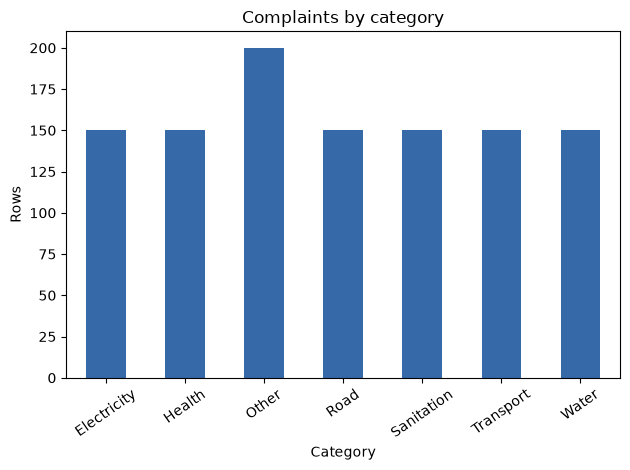

In [30]:
counts = data['category'].value_counts().sort_index()
display(counts.to_frame('rows'))
ax = counts.plot.bar(title='Complaints by category', ylabel='Rows', xlabel='Category', color='#3569a8')
ax.tick_params(axis='x', rotation=35)
plt.tight_layout(); plt.show()

,count,mean,std,min,25%,50%,75%,max
category,,,,,,,,
Electricity,150.0,54.4,11.6,28.0,46.0,56.0,62.8,79.0
Health,150.0,56.1,11.0,30.0,48.0,57.5,65.0,80.0
Other,200.0,50.8,10.6,26.0,43.0,49.0,59.0,76.0
Road,150.0,49.9,11.5,22.0,40.5,52.5,59.0,70.0
Sanitation,150.0,52.6,13.0,24.0,43.0,55.0,64.0,77.0
Transport,150.0,50.6,11.5,26.0,41.0,51.0,60.0,78.0
Water,150.0,50.6,11.9,25.0,41.0,51.0,61.0,74.0


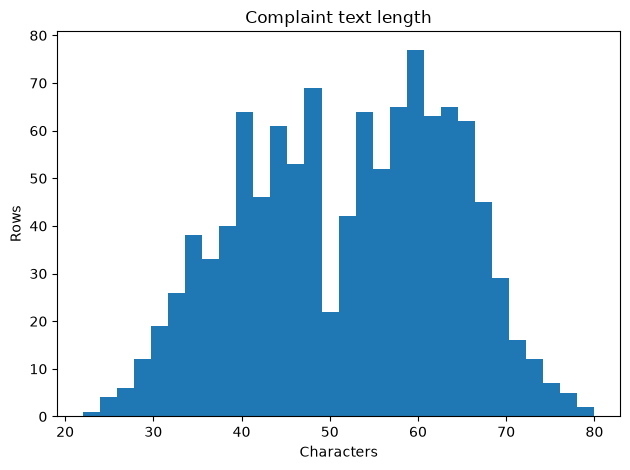

In [31]:
data['text_length'] = data['text'].str.len()
display(data.groupby('category')['text_length'].describe().round(1))
ax = data['text_length'].plot.hist(bins=30, title='Complaint text length', xlabel='Characters', ylabel='Rows')
plt.tight_layout(); plt.show()

In [32]:
if provenance is not None and 'language' in provenance.columns:
    print('Language labels from provenance:'); display(provenance['language'].value_counts(dropna=False))
else:
    print('Language distribution unavailable: reliable language metadata was not found.')

Language distribution unavailable: reliable language metadata was not found.


In [33]:
display(data.groupby('category', group_keys=False).head(2)[['category','text']].sort_values('category'))

,category,text
0,Electricity,Power keeps cutting out several times a day in...
1,Electricity,Our locality has frequent electricity interrup...
150,Health,No doctor was present at the public clinic dur...
151,Health,Patients arrived at the health centre but the ...
900,Other,My birth certificate application has been pend...
901,Other,I have not received an update on my birth cert...
300,Road,Deep potholes along the road force vehicles to...
301,Road,Several large holes have appeared in the lane ...
450,Sanitation,The waste collection vehicle has skipped our l...
451,Sanitation,Garbage bags are waiting outside because the c...


## 5. Leakage-aware development split
No scenario-family provenance is available. Similarity-connected complaints are grouped as a lexical safeguard; this cannot guarantee family separation.

In [34]:
group_vectorizer = TfidfVectorizer(analyzer='char_wb', ngram_range=(3,5), min_df=1, max_features=8000)
group_matrix = group_vectorizer.fit_transform(data['clean'])
similarity = cosine_similarity(group_matrix, dense_output=False)

In [35]:
similarity.data[similarity.data < 0.50] = 0
similarity.eliminate_zeros()
component_count, groups = connected_components(similarity, directed=False)
data['similarity_group'] = groups
print('Near-duplicate components:', component_count, '| rows:', len(data))

Near-duplicate components: 863 | rows: 1100


In [36]:
print('Mixed-label components:', int((data.groupby('similarity_group')['category'].nunique() > 1).sum()))
print('Largest component:', int(data['similarity_group'].value_counts().max()))
print('Grouping is a heuristic, not source provenance.')

Mixed-label components: 51
Largest component: 11
Grouping is a heuristic, not source provenance.


In [37]:
outer_cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
train_idx, validation_idx = next(outer_cv.split(data['clean'], data['category'], groups=data['similarity_group']))

In [38]:
dev = data.iloc[train_idx].reset_index(drop=True)
validation = data.iloc[validation_idx].reset_index(drop=True)
print('Development rows:', len(dev), '| validation rows:', len(validation))

Development rows: 880 | validation rows: 220


In [39]:
print('Normalized text overlap:', len(set(dev['duplicate_key']) & set(validation['duplicate_key'])))
print('Development classes:', dev['category'].value_counts().sort_index().to_dict())
print('Validation classes:', validation['category'].value_counts().sort_index().to_dict())

Normalized text overlap: 0
Development classes: {'Electricity': 120, 'Health': 120, 'Other': 160, 'Road': 120, 'Sanitation': 120, 'Transport': 120, 'Water': 120}
Validation classes: {'Electricity': 30, 'Health': 30, 'Other': 40, 'Road': 30, 'Sanitation': 30, 'Transport': 30, 'Water': 30}


In [40]:
assert set(dev['similarity_group']).isdisjoint(set(validation['similarity_group']))
assert set(dev['duplicate_key']).isdisjoint(set(validation['duplicate_key']))

## 6. Feature engineering
Use word and character TF-IDF. Validation features are transformed using vectorizers fitted on development rows only.

In [41]:
word_vectorizer = TfidfVectorizer(analyzer='word', ngram_range=(1,2), min_df=2, max_features=20000, sublinear_tf=True)
char_vectorizer = TfidfVectorizer(analyzer='char_wb', ngram_range=(3,5), min_df=2, max_features=3000, sublinear_tf=True)

In [42]:
X_dev_word = word_vectorizer.fit_transform(dev['clean'])
X_val_word = word_vectorizer.transform(validation['clean'])
print('Word feature matrices:', X_dev_word.shape, X_val_word.shape)

Word feature matrices: (880, 1573) (220, 1573)


In [43]:
X_dev_char = char_vectorizer.fit_transform(dev['clean'])
X_val_char = char_vectorizer.transform(validation['clean'])
print('Character feature matrices:', X_dev_char.shape, X_val_char.shape)

Character feature matrices: (880, 3000) (220, 3000)


## 7. Model training and evaluation
Tune on development data with identical grouped folds. Macro F1 gives every category equal weight.

In [44]:
def build_pipeline(classifier):
    features = FeatureUnion([('word', TfidfVectorizer(analyzer='word', ngram_range=(1,2), min_df=2, max_features=20000, sublinear_tf=True)),
        ('char', TfidfVectorizer(analyzer='char_wb', ngram_range=(3,5), min_df=2, max_features=3000, sublinear_tf=True))])
    return Pipeline([('features', features), ('classifier', classifier)])

In [45]:
inner_cv = StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=SEED + 1)
folds = list(inner_cv.split(dev['clean'], dev['category'], groups=dev['similarity_group']))
print('Grouped development folds:', len(folds))

Grouped development folds: 4


In [46]:
assert all(set(dev.similarity_group.iloc[a]).isdisjoint(set(dev.similarity_group.iloc[b])) for a,b in folds)
print('No similarity group crosses a CV fold.')

No similarity group crosses a CV fold.


In [47]:
svc = build_pipeline(SVC(kernel='linear', probability=True, class_weight='balanced', random_state=SEED))
svc_grid = {'classifier__C':[0.5, 1.0, 2.0]}
print('Estimator: SVC with a linear kernel.')

Estimator: SVC with a linear kernel.


In [48]:
logistic = build_pipeline(LogisticRegression(max_iter=2500, class_weight='balanced', random_state=SEED))
logistic_grid = {'classifier__C':[0.5, 1.0, 2.0]}

In [49]:
naive_bayes = build_pipeline(MultinomialNB())
naive_bayes_grid = {'classifier__alpha':[0.3, 1.0, 2.0]}
print('MultinomialNB uses nonnegative TF-IDF features.')

MultinomialNB uses nonnegative TF-IDF features.


In [50]:
random_forest = build_pipeline(RandomForestClassifier(class_weight='balanced_subsample', max_features='sqrt', min_samples_leaf=1, random_state=SEED, n_jobs=1))
random_forest_grid = {'classifier__n_estimators':[100, 200]}

In [51]:
svc_search = GridSearchCV(svc, svc_grid, scoring='f1_macro', cv=folds, refit=True, n_jobs=1, error_score='raise')
start = time.perf_counter(); svc_search.fit(dev['clean'], dev['category']); svc_seconds = time.perf_counter() - start
print('SVC best parameters:', svc_search.best_params_, '| CV macro F1:', round(svc_search.best_score_, 4), '| seconds:', round(svc_seconds, 2))

D:\grievance-redressal-system\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


D:\grievance-redressal-system\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


D:\grievance-redressal-system\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


D:\grievance-redressal-system\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


D:\grievance-redressal-system\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


...

D:\grievance-redressal-system\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


D:\grievance-redressal-system\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


D:\grievance-redressal-system\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


D:\grievance-redressal-system\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


SVC best parameters: {'classifier__C': 0.5} | CV macro F1: 0.8201 | seconds: 36.12


In [52]:
logistic_search = GridSearchCV(logistic, logistic_grid, scoring='f1_macro', cv=folds, refit=True, n_jobs=1, error_score='raise')
start = time.perf_counter(); logistic_search.fit(dev['clean'], dev['category']); logistic_seconds = time.perf_counter() - start
print('Logistic Regression best parameters:', logistic_search.best_params_, '| CV macro F1:', round(logistic_search.best_score_, 4), '| seconds:', round(logistic_seconds, 2))

Logistic Regression best parameters: {'classifier__C': 2.0} | CV macro F1: 0.8309 | seconds: 4.5


In [53]:
nb_search = GridSearchCV(naive_bayes, naive_bayes_grid, scoring='f1_macro', cv=folds, refit=True, n_jobs=1, error_score='raise')
start = time.perf_counter(); nb_search.fit(dev['clean'], dev['category']); nb_seconds = time.perf_counter() - start
print('MultinomialNB best parameters:', nb_search.best_params_, '| CV macro F1:', round(nb_search.best_score_, 4), '| seconds:', round(nb_seconds, 2))

MultinomialNB best parameters: {'classifier__alpha': 2.0} | CV macro F1: 0.796 | seconds: 2.01


In [54]:
rf_search = GridSearchCV(random_forest, random_forest_grid, scoring='f1_macro', cv=folds, refit=True, n_jobs=1, error_score='raise')
start = time.perf_counter(); rf_search.fit(dev['clean'], dev['category']); rf_seconds = time.perf_counter() - start
print('Random Forest best parameters:', rf_search.best_params_, '| CV macro F1:', round(rf_search.best_score_, 4), '| seconds:', round(rf_seconds, 2))

Random Forest best parameters: {'classifier__n_estimators': 200} | CV macro F1: 0.7881 | seconds: 11.97


In [55]:
searches = {'SVC':svc_search, 'Logistic Regression':logistic_search, 'MultinomialNB':nb_search, 'Random Forest':rf_search}
training_seconds = {'SVC':svc_seconds, 'Logistic Regression':logistic_seconds, 'MultinomialNB':nb_seconds, 'Random Forest':rf_seconds}
validation_predictions = {name: search.predict(validation['clean']) for name,search in searches.items()}

In [56]:
labels = sorted(data['category'].unique())
results = []
reports = {}
matrices = {}

In [57]:
for name, pred in validation_predictions.items():
    truth = validation['category']
    reports[name] = classification_report(truth, pred, labels=labels, output_dict=True, zero_division=0)
    matrices[name] = confusion_matrix(truth, pred, labels=labels)

In [58]:
for name, pred in validation_predictions.items():
    truth = validation['category']
    results.append({'model':name, 'accuracy':accuracy_score(truth,pred), 'macro_precision':precision_score(truth,pred,labels=labels,average='macro',zero_division=0),
      'macro_recall':recall_score(truth,pred,labels=labels,average='macro',zero_division=0), 'macro_f1':f1_score(truth,pred,labels=labels,average='macro',zero_division=0),
      'weighted_f1':f1_score(truth,pred,labels=labels,average='weighted',zero_division=0), 'training_seconds':training_seconds[name]})

In [59]:
validation_results = pd.DataFrame(results).sort_values(['macro_f1','weighted_f1','accuracy'], ascending=False).reset_index(drop=True)
display(validation_results)

,model,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,training_seconds
0,Logistic Regression,0.904545,0.910359,0.905952,0.907517,0.904601,4.498592
1,SVC,0.872727,0.884466,0.873810,0.877529,0.874004,36.121212
2,Random Forest,0.840909,0.874154,0.836905,0.845220,0.841124,11.969102
3,MultinomialNB,0.800000,0.829651,0.797619,0.806958,0.802475,2.008334


In [60]:
print('Per-class precision, recall, F1 and support:')
for name, report in reports.items():
    print(name); display(pd.DataFrame(report).T.loc[labels, ['precision','recall','f1-score','support']])

Per-class precision, recall, F1 and support:
SVC


,precision,recall,f1-score,support
Electricity,1.000000,0.900000,0.947368,30.0
Health,0.774194,0.800000,0.786885,30.0
Other,0.755556,0.850000,0.800000,40.0
Road,0.906250,0.966667,0.935484,30.0
Sanitation,0.923077,0.800000,0.857143,30.0
Transport,0.965517,0.933333,0.949153,30.0
Water,0.866667,0.866667,0.866667,30.0


Logistic Regression


,precision,recall,f1-score,support
Electricity,1.000000,0.966667,0.983051,30.0
Health,0.870968,0.900000,0.885246,30.0
Other,0.813953,0.875000,0.843373,40.0
Road,0.935484,0.966667,0.950820,30.0
Sanitation,0.888889,0.800000,0.842105,30.0
Transport,0.966667,0.966667,0.966667,30.0
Water,0.896552,0.866667,0.881356,30.0


MultinomialNB


,precision,recall,f1-score,support
Electricity,1.000000,0.933333,0.965517,30.0
Health,0.913043,0.700000,0.792453,30.0
Other,0.607143,0.850000,0.708333,40.0
Road,0.848485,0.933333,0.888889,30.0
Sanitation,0.800000,0.666667,0.727273,30.0
Transport,0.888889,0.800000,0.842105,30.0
Water,0.750000,0.700000,0.724138,30.0


Random Forest


,precision,recall,f1-score,support
Electricity,1.000000,0.966667,0.983051,30.0
Health,0.913043,0.700000,0.792453,30.0
Other,0.637931,0.925000,0.755102,40.0
Road,0.875000,0.933333,0.903226,30.0
Sanitation,0.900000,0.600000,0.720000,30.0
Transport,0.965517,0.933333,0.949153,30.0
Water,0.827586,0.800000,0.813559,30.0


In [61]:
for name in searches:
    print('Classification report:', name)
    print(classification_report(validation['category'], validation_predictions[name], labels=labels, zero_division=0))

Classification report: SVC
              precision    recall  f1-score   support

 Electricity       1.00      0.90      0.95        30
      Health       0.77      0.80      0.79        30
       Other       0.76      0.85      0.80        40
        Road       0.91      0.97      0.94        30
  Sanitation       0.92      0.80      0.86        30
   Transport       0.97      0.93      0.95        30
       Water       0.87      0.87      0.87        30

    accuracy                           0.87       220
   macro avg       0.88      0.87      0.88       220
weighted avg       0.88      0.87      0.87       220

Classification report: Logistic Regression
              precision    recall  f1-score   support

 Electricity       1.00      0.97      0.98        30
      Health       0.87      0.90      0.89        30
       Other       0.81      0.88      0.84        40
        Road       0.94      0.97      0.95        30
  Sanitation       0.89      0.80      0.84        30
   Trans

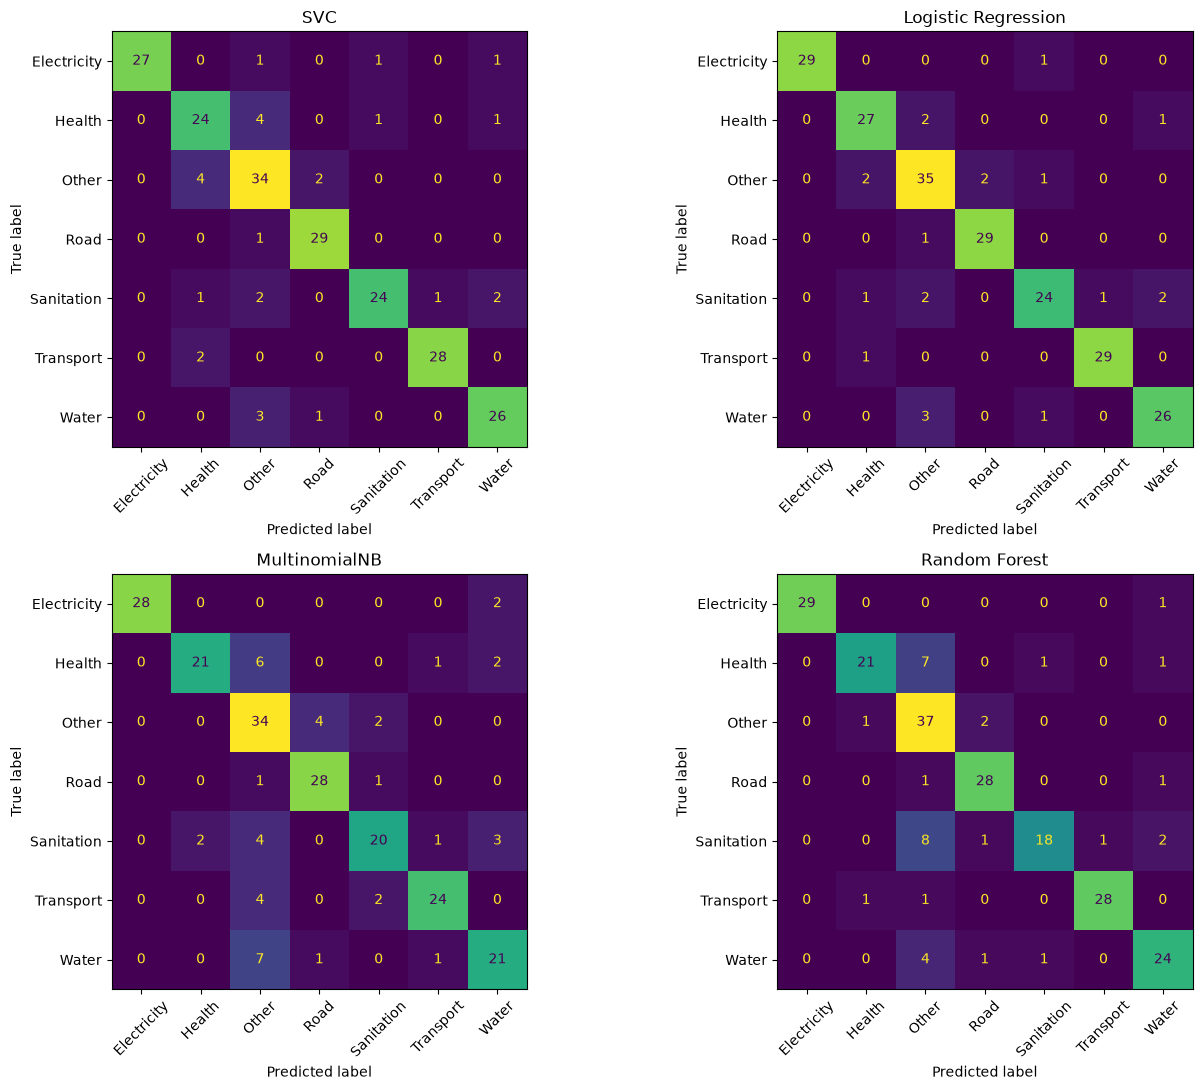

In [62]:
fig, axes = plt.subplots(2, 2, figsize=(14, 11))
for ax, name in zip(axes.ravel(), searches):
    ConfusionMatrixDisplay(matrices[name], display_labels=labels).plot(ax=ax, xticks_rotation=45, colorbar=False, values_format='d'); ax.set_title(name)
plt.tight_layout(); plt.show()

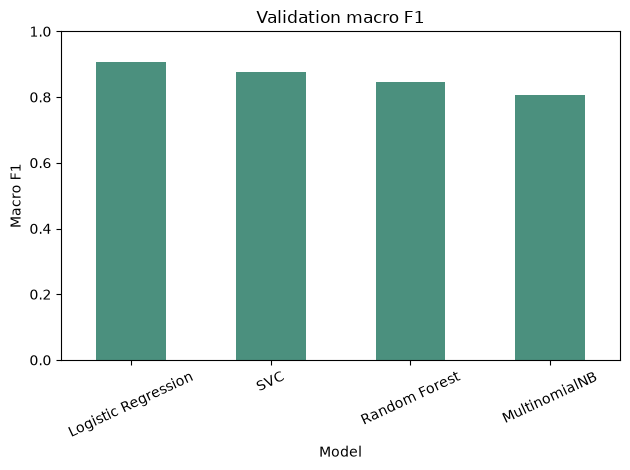

In [63]:
ax = validation_results.set_index('model')['macro_f1'].plot.bar(title='Validation macro F1', ylabel='Macro F1', xlabel='Model', color='#4b907e')
ax.set_ylim(0, 1); ax.tick_params(axis='x', rotation=25)
plt.tight_layout(); plt.show()

In [64]:
winner = validation_results.iloc[0]
winning_name = winner['model']
print('Validation winner:', winning_name, '| macro F1:', round(winner['macro_f1'], 4))
print('Winner chosen automatically by validation macro F1.')

Validation winner: Logistic Regression | macro F1: 0.9075
Winner chosen automatically by validation macro F1.


In [65]:
winning_search = searches[winning_name]
print('Winning settings:', winning_search.best_params_)
print('Grouped CV macro F1 mean:', round(winning_search.best_score_, 4), '| SD:', round(winning_search.cv_results_['std_test_score'][winning_search.best_index_], 4))

Winning settings: {'classifier__C': 2.0}
Grouped CV macro F1 mean: 0.8309 | SD: 0.0433


## 8. Deployment-ready candidate saving
Freeze the validation-selected settings, refit on training data, and save a separate candidate. Production remains unchanged.

In [66]:
final_pipeline = winning_search.best_estimator_
final_pipeline.fit(data['clean'], data['category'])
feature_union = final_pipeline.named_steps['features']

In [67]:
word_fitted = dict(feature_union.transformer_list)['word']
char_fitted = dict(feature_union.transformer_list)['char']
classifier = final_pipeline.named_steps['classifier']

In [68]:
assert hasattr(classifier, 'predict_proba')
print('Candidate labels:', list(classifier.classes_))
print('Probability interface available for serving compatibility.')

Candidate labels: ['Electricity', 'Health', 'Other', 'Road', 'Sanitation', 'Transport', 'Water']
Probability interface available for serving compatibility.


In [69]:
candidate_payload = {'pipeline':final_pipeline, 'word_vectorizer':word_fitted, 'char_vectorizer':char_fitted, 'classifier':classifier, 'labels':list(classifier.classes_)}
assert not CANDIDATE_PATH.exists() and not METADATA_PATH.exists(), 'Refusing to overwrite candidate files.'
joblib.dump(candidate_payload, CANDIDATE_PATH)
print('Saved candidate:', CANDIDATE_PATH)

Saved candidate: D:\grievance-redressal-system\backend\models\grievance_classifier_synthetic_research_simple_candidate_20261024.joblib


In [70]:
validation_metrics = {key:float(winner[key]) for key in ['accuracy','macro_precision','macro_recall','macro_f1','weighted_f1']}
metadata = {'artifact':CANDIDATE_PATH.name, 'selected_model':winning_name, 'selected_params':winning_search.best_params_, 'validation_metrics':validation_metrics, 'dataset':str(DATA_PATH.relative_to(ROOT)),
    'dataset_sha256':hashlib.sha256(DATA_PATH.read_bytes()).hexdigest(), 'feature_configuration':'word (1,2) + char_wb (3,5) TF-IDF', 'class_labels':list(classifier.classes_), 'random_seed':SEED,
    'holdout_evaluation':'PENDING; no untouched independent holdout found', 'production_replacement':False}

In [71]:
METADATA_PATH.write_text(json.dumps(metadata, ensure_ascii=False, indent=2) + '\n', encoding='utf-8')
print('Saved metadata:', METADATA_PATH)

Saved metadata: D:\grievance-redressal-system\backend\models\grievance_classifier_synthetic_research_simple_candidate_20261024.metadata.json


In [72]:
loaded_candidate = GrievanceModel.load_artifact(CANDIDATE_PATH)
smoke_text = 'The service has been unreliable for several weeks, and repeated complaints have not resolved the issue.'
print('Loaded candidate smoke prediction:', loaded_candidate.predict(smoke_text))

Loaded candidate smoke prediction: {'category': 'other', 'confidence': 0.428, 'reason': 'low confidence (0.43 < 0.5)'}


## Validation errors and limitations
The 120-row holdout has prior evaluation exposure; the 614-row template holdout was reused too. Final independent holdout evaluation remains pending.

In [73]:
predicted = validation_predictions[winning_name]
error_mask = predicted != validation['category'].to_numpy()
errors = validation.loc[error_mask, ['text','category']].copy()
errors['predicted_category'] = np.asarray(predicted)[error_mask]
print('Validation errors:', len(errors), '/', len(validation)); display(errors.head(20))

Validation errors: 21 / 220


,text,category,predicted_category
9,Amcha meter band padla aahe.,Electricity,Sanitation
47,One staff member is handling registration for ...,Health,Other
52,Basic hygiene supplies are missing from the tr...,Health,Water
57,Sarkari prayogshalet aaj tapasni hot nahi.,Health,Other
87,Rastyatil khaddyanchya takrarivar koni ale nahi.,Road,Other
91,The roadside gutter is clogged with rubbish an...,Sanitation,Water
92,Waste buildup is stopping water from flowing t...,Sanitation,Water
97,Nali se bahut badbu aa rahi hai.,Sanitation,Health
99,बाजारपेठेतील सार्वजनिक स्वच्छतागृह स्वच्छ नाही.,Sanitation,Other
104,There is no designated waste bin near the bus ...,Sanitation,Transport


In [74]:
print('Training rows:', len(data), '| development/validation:', len(dev), '/', len(validation))
print('No family provenance or trustworthy language labels were available.')
print('Lexical grouping cannot guarantee scenario-family separation.')

Training rows: 1100 | development/validation: 880 / 220
No family provenance or trustworthy language labels were available.
Lexical grouping cannot guarantee scenario-family separation.


In [75]:
print('Other is modeled as a supervised seventh class.')
print('This measures seven-class classification, not separate out-of-scope detection.')

Other is modeled as a supervised seventh class.
This measures seven-class classification, not separate out-of-scope detection.


In [76]:
print('120-row holdout found:', holdout is not None)
print('Prior exposure means it is development/debug evidence, not a final test.')
print('Independent final holdout evaluation: PENDING.')

120-row holdout found: True
Prior exposure means it is development/debug evidence, not a final test.
Independent final holdout evaluation: PENDING.


In [77]:
PRODUCTION_PATH = ROOT / 'backend/models/grievance_classifier_v2_candidate.joblib'
print('Production artifact exists:', PRODUCTION_PATH.is_file())
print('Research candidate is separate:', CANDIDATE_PATH != PRODUCTION_PATH)

Production artifact exists: False
Research candidate is separate: True


In [78]:
if PRODUCTION_PATH.is_file():
    existing_model = GrievanceModel.load_artifact(PRODUCTION_PATH)
    print('Production smoke prediction:', existing_model.predict('A pothole is blocking the road near the bus stop.'))

## Summary
Results are validation results on this synthetic dataset, not independent real-world performance.

In [79]:
display(validation_results)
print('Best model:', winning_name, '| validation macro F1:', round(float(winner['macro_f1']), 4))
print('Candidate saved separately; production artifact untouched.')
print('No untouched independent holdout located; final evaluation pending.')

,model,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,training_seconds
0,Logistic Regression,0.904545,0.910359,0.905952,0.907517,0.904601,4.498592
1,SVC,0.872727,0.884466,0.873810,0.877529,0.874004,36.121212
2,Random Forest,0.840909,0.874154,0.836905,0.845220,0.841124,11.969102
3,MultinomialNB,0.800000,0.829651,0.797619,0.806958,0.802475,2.008334


Best model: Logistic Regression | validation macro F1: 0.9075
Candidate saved separately; production artifact untouched.
No untouched independent holdout located; final evaluation pending.
